[nltk_data] Downloading package stopwords to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data] Downloading package punkt to /home/nineleaps/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


--- Naive Bayes Evaluation ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       322
           1       1.00      1.00      1.00       372

    accuracy                           1.00       694
   macro avg       1.00      1.00      1.00       694
weighted avg       1.00      1.00      1.00       694



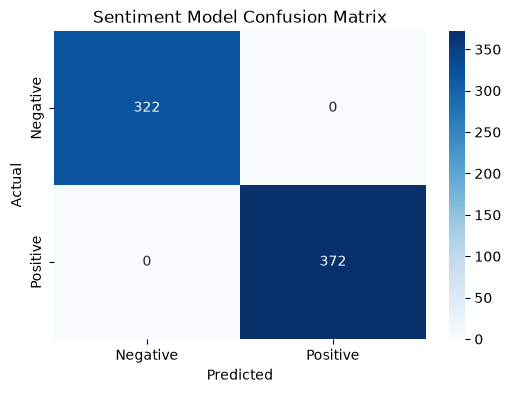

--- VADER vs Actual Accuracy ---
VADER Accuracy: 0.7662
--- Top Complaint Themes (n-grams) ---
['driver stuck' 'driver stuck traffic' 'experience food'
 'experience food cold' 'food cold' 'long arrive' 'stuck traffic'
 'stuck traffic forever' 'terrible experience' 'terrible experience food'
 'took way' 'took way long' 'traffic forever' 'way long' 'way long arrive']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Download required NLTK datasets (run this once)
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('punkt')
nltk.download('punkt_tab')

# 1. Load Data
reviews = pd.read_csv('../data/raw/reviews.csv')

# 2. Text Cleaning Preparation
# Map ratings to binary sentiment: 4-5 is Positive (1), 1-2 is Negative (0). 
# We drop 3 (Neutral) for clearer classification boundaries.
reviews_filtered = reviews[reviews['rating'] != 3].copy()
reviews_filtered['sentiment_target'] = np.where(reviews_filtered['rating'] > 3, 1, 0)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    tokens = nltk.word_tokenize(text)
    # Remove punctuation, stop-words, and lemmatize
    cleaned_tokens = [
        lemmatizer.lemmatize(word) 
        for word in tokens 
        if word.isalpha() and word not in stop_words
    ]
    return " ".join(cleaned_tokens)

reviews_filtered['cleaned_review'] = reviews_filtered['review_text'].apply(clean_text)

# 3. TF-IDF
tfidf = TfidfVectorizer(max_features=1000, ngram_range=(1, 2))
X = tfidf.fit_transform(reviews_filtered['cleaned_review'])
y = reviews_filtered['sentiment_target']

# 4. Sentiment Modeling (Naive Bayes)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
y_pred = nb_model.predict(X_test)

print("--- Naive Bayes Evaluation ---")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Negative', 'Positive'], 
            yticklabels=['Negative', 'Positive'])
plt.title('Sentiment Model Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# 5. VADER Lexicon Application
sid = SentimentIntensityAnalyzer()
    
def get_vader_sentiment(text):
    if not isinstance(text, str):
        return 0
    scores = sid.polarity_scores(text)
    # VADER compound score threshold
    if scores['compound'] >= 0.05:
        return 1
    else:
        return 0

reviews_filtered['vader_sentiment'] = reviews_filtered['review_text'].apply(get_vader_sentiment)
    
print("--- VADER vs Actual Accuracy ---")
print(f"VADER Accuracy: {accuracy_score(reviews_filtered['sentiment_target'], reviews_filtered['vader_sentiment']):.4f}")

# 6. Insights: Top Customer Complaints
negative_reviews = reviews_filtered[reviews_filtered['sentiment_target'] == 0]
tfidf_neg = TfidfVectorizer(max_features=20, stop_words='english', ngram_range=(2,3))
neg_matrix = tfidf_neg.fit_transform(negative_reviews['cleaned_review'])
print("--- Top Complaint Themes (n-grams) ---")
print(tfidf_neg.get_feature_names_out())